# LTE Model Computation and Plotting Tutorial

This tutorial demonstrates how to create Local Thermal Equilibrium (LTE) plasma models and compute synthetic LIBS spectra.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import libskit

# Enable interactive plots
%matplotlib widget

print(libskit.__version__)

1.4.1.dev1+ga4b498b3c.d20260318


## 1. Basic LTE Model Creation

An LTE model represents a plasma in local thermal equilibrium with specified elemental composition, temperature, electron density, and optical path length.

In [ ]:
# Create a simple LTE model with iron
elements = {"Fe": 1.0}  # 100% iron
temperature = 10000.0   # Temperature in Kelvin
electron_density = 1e23 # Electron density in m^-3
length = 1e-3          # Plasma length in meters

lte_model = libskit.LTEModel(elements, temperature, electron_density, length)

print("LTE Model Parameters:")
print(f"Elements: {lte_model.element_ratio}")
print(f"Temperature: {lte_model.temperature} K")
print(f"Electron density: {lte_model.electron_density:.2e} m^-3") 
print(f"Length: {lte_model.length:.2e} m")

## 2. Computing and Plotting a spectrum

Let's look at the syntax used in libskit and plot the irradiance of a simple LTE model.

In [3]:
# Define wavelength range
wavelengths = np.arange(200, 700, 0.1)  # 400-700 nm range

# Calculate irradiance spectrum
irradiance = lte_model.calculate_irradiance(wavelengths)

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(wavelengths, irradiance, 'b-', linewidth=1)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Iron LTE Spectrum (T=10000K, ne=1e23 m⁻³)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

IndexError: unordered_map::at

## 3. Multi-Element Plasma

Create a more complex plasma with multiple elements.

In [ ]:
# Create multi-element plasma (typical geological composition)
multi_elements = {
    "Si": 0.30,   # Silicon
    "Al": 0.20,   # Aluminum  
    "Fe": 0.25,   # Iron
    "Ca": 0.15,   # Calcium
    "Na": 0.10    # Sodium
}

multi_lte = libskit.LTEModel(multi_elements, temperature, electron_density, length)

# Calculate spectrum
multi_irradiance = multi_lte.calculate_irradiance(wavelengths)

# Plot comparison
plt.figure(figsize=(12, 7))
plt.plot(wavelengths, irradiance, 'b-', label='Pure Fe', alpha=0.7)
plt.plot(wavelengths, multi_irradiance, 'r-', label='Multi-element', alpha=0.7)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Comparison: Pure Iron vs Multi-element Plasma')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Multi-element composition:")
for element, ratio in multi_elements.items():
    print(f"  {element}: {ratio:.2f}")

## 4. Temperature Effects

Investigate how temperature affects the spectrum.

In [ ]:
# Test different temperatures
temperatures = [8000, 10000, 12000, 15000]  # Kelvin
colors = ['blue', 'green', 'orange', 'red']

plt.figure(figsize=(12, 8))

for i, temp in enumerate(temperatures):
    temp_model = libskit.LTEModel({"Ca": 1.0}, temp, electron_density, length)
    temp_irradiance = temp_model.calculate_irradiance(wavelengths)
    
    plt.plot(wavelengths, temp_irradiance, color=colors[i], 
             label=f'T = {temp} K', linewidth=1.5, alpha=0.8)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Temperature Effect on Calcium Spectrum')
plt.legend()
plt.grid(True, alpha=0.3)
#plt.yscale('log')  # Log scale to see differences better
plt.tight_layout()
plt.show()

## 5. Electron Density Effects

Examine how electron density affects line intensities.

In [ ]:
# Test different electron densities
densities = [1e22, 5e22, 1e23, 5e23]  # m^-3
colors = ['cyan', 'blue', 'orange', 'red']

plt.figure(figsize=(12, 8))

for i, density in enumerate(densities):
    density_model = libskit.LTEModel({"Ca": 1.0}, temperature, density, length)
    density_irradiance = density_model.calculate_irradiance(wavelengths)
    
    plt.plot(wavelengths, density_irradiance, color=colors[i], 
             label=f'ne = {density:.1e} m⁻³', linewidth=1.5, alpha=0.8)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Electron Density Effect on Calcium Spectrum')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Instrumental Broadening

Real spectrometers have finite resolution. Let's simulate instrumental effects.

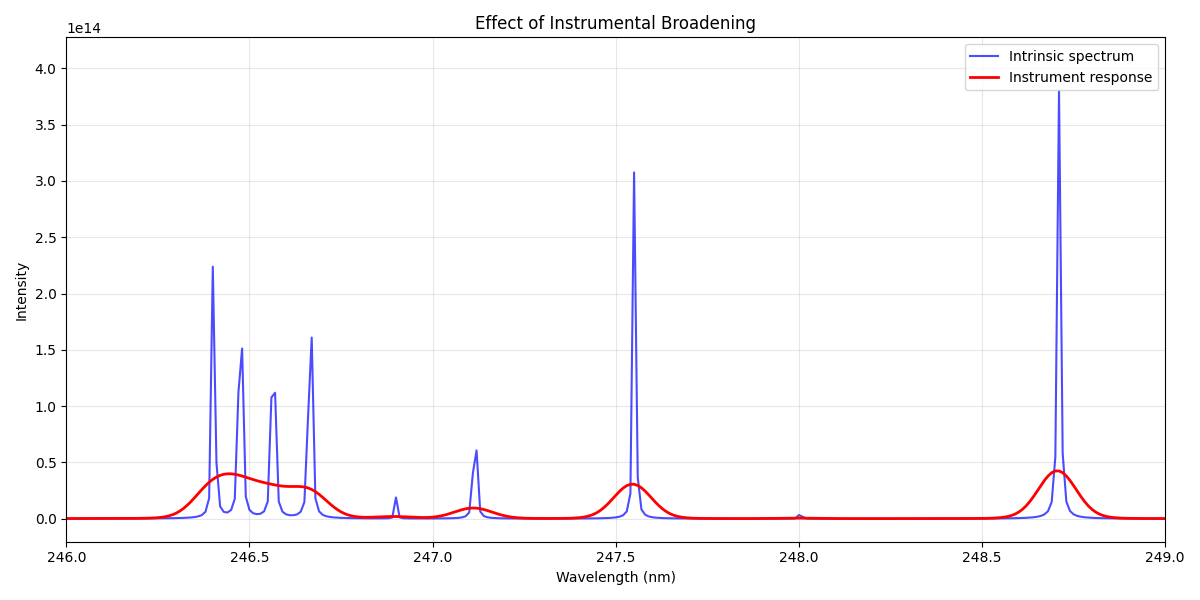

In [7]:
# Create a spectrometer model (broadens the irradiance using a Voigt profile)
spectrometer = libskit.GenericSpectrometer(0.05, 0.001) # gauss width, lorentz width

# Calculate spectrum with instrumental broadening
broadened_spectrum = spectrometer.calculate_spectrum(wavelengths, lte_model)

plt.figure(figsize=(12, 6))
plt.plot(wavelengths, irradiance.real, 'b-', label='Intrinsic spectrum', alpha=0.7)
plt.plot(wavelengths, broadened_spectrum.real, 'r-', label='Instrument response', linewidth=2)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Intensity')
plt.title('Effect of Instrumental Broadening')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(246, 249)  # Zoom in to see broadening effect
plt.tight_layout()
plt.show()

## 7. Population Fractions

Examine the population distribution across ionization states.

In [8]:
# Get population fractions for the multi-element model
pop_fractions = multi_lte.get_population_fractions()

print("Population fractions by element:")
for element, fractions in pop_fractions.items():
    print(f"\n{element}:")
    for i, frac in enumerate(fractions[:5]):  # Show first 5 ionization states
        if frac > 1e-5:  # Only show significant populations
            print(f"  {element} {i+1}+: {frac:.4f}")

Population fractions by element:

Al:
  Al 1+: 0.1270
  Al 2+: 0.8730
  Al 3+: 0.0000

Ca:
  Ca 1+: 0.0369
  Ca 2+: 0.9497
  Ca 3+: 0.0134

Fe:
  Fe 1+: 0.1507
  Fe 2+: 0.8492
  Fe 3+: 0.0001

Na:
  Na 1+: 0.0450
  Na 2+: 0.9550

Si:
  Si 1+: 0.3391
  Si 2+: 0.6609
  Si 3+: 0.0000


## 8. Parameter Modification

Demonstrate how to modify LTE model parameters dynamically.

In [ ]:
# Create a copy of the model to modify
modified_model = libskit.LTEModel({"Si": 1.0}, 10000, 1e23, 1e-3)

print("Original parameters:")
print(f"Temperature: {modified_model.temperature} K")

# Modify temperature using parameter interface
modified_model.temperature =  15000.0
print(f"Modified temperature: {modified_model.temperature} K")

# Modify electron density
modified_model.electron_density =  2e23
print(f"Modified electron density: {modified_model.electron_density:.2e} m^-3")

# Calculate new spectrum
modified_irradiance = modified_model.calculate_irradiance(wavelengths)

plt.figure(figsize=(10, 6))
plt.plot(wavelengths, modified_irradiance, 'g-', linewidth=1.5)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Irradiance (W/m²/nm/sr)')
plt.title('Silicon Spectrum (Modified Parameters)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Configuring Accuracy

libskit uses a single `accuracy` parameter that defines the noise floor as a fraction of the tallest peak height. This controls:

- **Which emission lines are included:** lines whose peak height falls below `accuracy × max_peak_height` are discarded entirely.
- **Where broadening wings are truncated:** broadening contributions are stopped once the spectral density drops below `accuracy × max_peak_height`.

A smaller value keeps more lines and longer wings (more accurate but slower). A larger value is faster but discards more detail.

In [3]:
# Check current accuracy setting
print(f"Current accuracy: {libskit.get_accuracy()}")
print("\nThis defines the noise floor as a fraction of the tallest peak height.")
print("Lines with peak height < accuracy × max_peak_height are discarded.")
print("Broadening wings are truncated at the same threshold.")

Current accuracy: 1e-05

This defines the noise floor as a fraction of the tallest peak height.
Lines with peak height < accuracy × max_peak_height are discarded.
Broadening wings are truncated at the same threshold.


### Demonstrating Accuracy Impact

Let's create a multi-element plasma and compare spectra at different accuracy levels.

In [ ]:
# Create a multi-element plasma for testing
test_elements = {"Ca": 0.4, "Si": 0.3, "Fe": 0.2, "Al": 0.1}
test_model = libskit.LTEModel(test_elements, 8000, 1e23, 1e-3)

# Define a focused wavelength range for comparison
test_wavelengths = np.arange(250, 400, 0.001)

# Calculate spectra at three accuracy levels
accuracy_levels = [1e-5, 1e-4, 1e-3, 1e-2]
spectra = {}
for acc in accuracy_levels:
    libskit.set_accuracy(acc)
    spectra[acc] = test_model.calculate_irradiance(test_wavelengths)
    total = np.sum(spectra[acc])
    print(f"accuracy={acc:.0e}: total irradiance = {total:.3e}")

# Restore default
libskit.set_accuracy(1e-5)

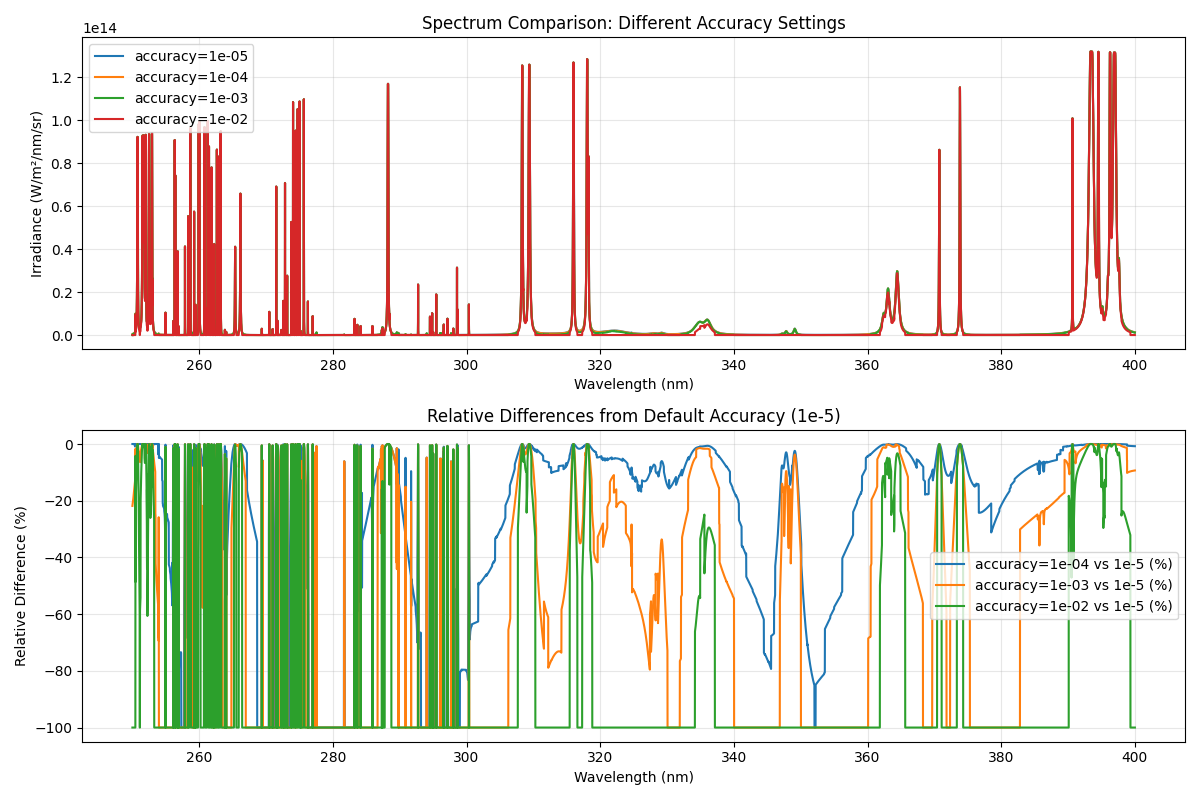

In [13]:
# Plot comparison of different accuracy settings
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Top: overlay spectra
for (acc, spec) in spectra.items():
    axes[0].plot(test_wavelengths, spec, label=f'accuracy={acc:.0e}', linewidth=1.5)
axes[0].set_xlabel('Wavelength (nm)')
axes[0].set_ylabel('Irradiance (W/m²/nm/sr)')
axes[0].set_title('Spectrum Comparison: Different Accuracy Settings')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Bottom: relative differences from the tightest accuracy (1e-6)
reference = spectra[1e-5]
for acc in [1e-4, 1e-3, 1e-2]:
    # Avoid division by zero where reference is negligible
    mask = reference > 1e-10 * np.max(reference)
    diff = np.full_like(reference, np.nan)
    diff[mask] = (spectra[acc][mask] - reference[mask]) / reference[mask] * 100
    axes[1].plot(test_wavelengths, diff, label=f'accuracy={acc:.0e} vs 1e-5 (%)', linewidth=1.5)
axes[1].set_xlabel('Wavelength (nm)')
axes[1].set_ylabel('Relative Difference (%)')
axes[1].set_title('Relative Differences from Default Accuracy (1e-5)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()